# **Modelos de conteo y modelos de mezcla**

In [ ]:
# ==========================
# Entorno PyMC + PreliZ para Colab actual
# ==========================

!pip uninstall -y \
    pymc \
    pytensor \
    preliz \
    arviz \
    arviz_stats \
    numba \
    llvmlite


!pip install -q --no-cache-dir \
    "numpy==2.0.2" \
    "scipy==1.16.1" \
    "pandas==2.3.0" \
    "matplotlib==3.10.0" \
    "arviz==0.22.0" \
    "pytensor==2.38.3" \
    "pymc==5.28.5" \
    "preliz==0.20.0" \
    "xarray" \
    "bambi==0.15.0"

print("Instalación terminada.")
print("Ahora reiniciá la sesión: Runtime → Restart session")

In [ ]:
import sys
import numpy as np
import scipy
import pandas as pd
import arviz as az
import pytensor
import pymc as pm
import preliz as pz
import xarray as xr
import bambi as bmb

import matplotlib.pyplot as plt
from scipy.stats import beta

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("ArviZ:", az.__version__)
print("PyTensor:", pytensor.__version__)
print("PyMC:", pm.__version__)
print("PreliZ:", pz.__version__)
print("Xarray:", xr.__version__)
print("bambi:", bmb.__version__)

In [ ]:
import matplotlib.pyplot as plt

## ¿Qué problema queremos resolver con un modelo de Mezcla?

Muchas veces una sola distribución no siempre alcanza para describir bien nuestros datos. Por ejemplo, si tenemos una población que en realidad está formada por *distintos subgrupos*, puede que cada subgrupo tenga un comportamiento relativamente simple, pero que cuando los observamos todos juntos aparezca una distribución mucho más compleja.

Los **modelos de mezcla** en lugar de intentar describir toda la distribución con una única distribución simple, busca construirla combinando varias de ellas.

Y esto tiene dos interpretaciones posibles. A veces los componentes tienen una interpretación concreta, como diferentes subpoblaciones. pero otras veces no necesitamos que representen grupos reales: simplemente los usamos para conseguir una distribución más flexible.

**¿Y qué sucede con la perspectiva bayesiana?:**

En el enfoque bayesiano, además, no tenemos que conocer exactamente los parámetros ni las asignaciones de cada observación, sino que podemos incorporar esa incertidumbre al modelo.

Para verlo de una manera más intuitiva, imaginemos que nuestra población está formada por dos grupos, y supongamos que tenemos observaciones de los dos grupos mezcladas, pero no sabemos a qué grupo pertenece cada individuo.
Si conociéramos esa información, sería muy sencillo: podríamos separar los datos y ajustar un modelo para cada grupo.

*El problema aparece justamente porque esa información no está observada.* Entonces nos queda introducir una variable que represente esa pertenencia: para cada observación, esta variable nos dice, conceptualmente, si el dato fue generado por el primer componente o por el segundo.

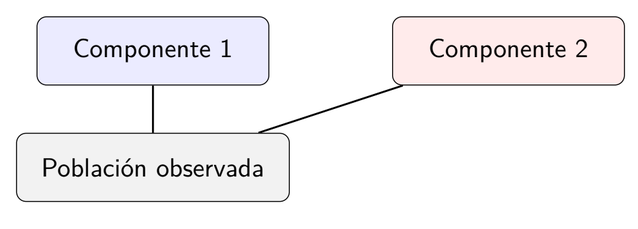

Como nosotros no observamos esa variable, la llamamos *variable latente*.



# Mezclas finitas

Formalmente, una mezcla finita combina un número fijo $K$ de distribuciones mediante pesos:

$$p(y)=\sum_{k=1}^{K} w_k\,p_k(y)$$



* $p_k(y)$ es la distribución del componente $k$.
* $w_k$ es el peso asignado al componente $k$.
* $w_k\geq 0$ y

$$\sum_{k=1}^{K}w_k=1.$$

Los pesos tienen que ser no negativos y sumar uno, porque podemos interpretarlos como probabilidades.

Una manera muy útil de pensar el modelo es como un proceso de dos pasos:
Primero elegimos qué componente vamos a utilizar, de acuerdo con los pesos. Y después, una vez elegido ese componente, generamos el dato utilizando su distribución.


Por ejemplo, pensemos en una mezcla de $K$ Gaussianas


$$p(y)=
\sum_{k=1}^{K}
w_k\,\mathcal N(y\mid\mu_k,\sigma_k^2)$$


Cada componente tiene sus propios parámetros:

* $\mu_k$: ubicación del componente $k$.
* $\sigma_k$: dispersión del componente $k$.
* $w_k$: peso del componente $k$.


Entonces, en lugar de tener una única Normal para representar todos los datos, tenemos varias Normales que pueden estar ubicadas en lugares diferentes y tener distintas dispersiones. Esto nos permite representar formas que una única Normal no podría representar.

Y hay algo importante para no llevarnos una interpretación demasiado fuerte: no necesariamente tenemos que decir que cada Gaussiana representa una población real. Puede ser que sí, pero también puede ocurrir simplemente que la mezcla sea una herramienta matemática para aproximar una distribución compleja.



### La variable latente

Vamos a comenzar a formalizar la idea de pertenencia que vimos al principio.

Introducimos una variable categórica $z_i$ para cada observación:

$$z_i\in\{1,\ldots,K\}$$

Esta variable indica qué componente genera $y_i$.

$$z_i\sim\operatorname{Categorical}(w)
$$

y, condicionalmente a $z_i$,

$$
y_i\mid z_i=k
\sim
p_k(y_i\mid\theta_k)
$$

* $z_i$ es latente: no lo observamos directamente.
* $\theta_k$ contiene los parámetros del componente $k$.
* La mezcla aparece porque no conocemos el valor de $z_i$.

Y esto cambia bastante la interpretación del modelo: no estamos simplemente ajustando varias distribuciones, sino que estamos intentando inferir simultáneamente cómo son esos componentes y, además, qué tan compatible es cada observación con cada uno de ellos.

### Dos formas de mirar el mismo modelo

Entonces, tenemos dos formas de escribir exactamente la misma idea.

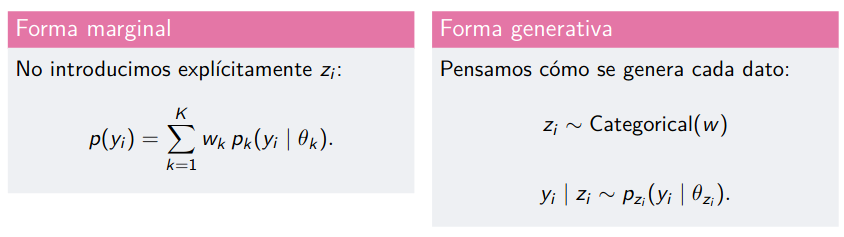



i) Por un lado podemos trabajar con la forma generativa, que es probablemente la más intuitiva: primero elegimos $z_i$ y después generamos $y_i$ condicionado a ese componente.

ii) Pero también podemos preguntarnos qué distribución tiene $y_i$ si no observamos $z_i$. Como $z_i$ puede tomar varios valores posibles, debemos considerar todos los casos y ponderarlos por sus probabilidades. A esto se lo llama la *suma marginal*.


### El modelo bayesiano de mezcla Gaussiana

Hasta este momento hablamos de los pesos y de los parámetros de los componentes como si fueran conocidos, pero en realidad tampoco los conocemos.
Entonces debemos estructurar un modelo donde asignemos distribuciones a priori.

Una especificación posible es:


$$w \sim Dirichlet(\alpha),$$

$$\mu_k \sim \mathcal N(\mu_0,\tau^2),\qquad k=1,\ldots,K,$$

$$\sigma_k \sim p(\sigma),$$

$$z_i \sim Categorical(w),$$

$$y_i\mid z_i=k \sim
\mathcal N(\mu_k,\sigma_k^2).$$


* El prior Dirichlet garantiza que los pesos sean no negativos y sumen uno.
* Los priors de $\mu_k$ y $\sigma_k$ incorporan información previa sobre los componentes.
* Las asignaciones $z_i$ son variables latentes.

NOTA: No existe una única especificación correcta: los priors deben
adaptarse al problema y a la escala de los datos.


Una observación importante es que todo esto se infiere conjuntamente. No es necesario decidir de previamente cuál es el componente de cada observación.

### Probabilidad de pertenencia a un componente

Una vez observados los datos, podemos estudiar:

$$
P(z_i=k\mid y_i,\text{datos}).
$$

Estas probabilidades se conocen como ***probabilidades de asignación***.

No necesariamente tenemos una clasificación determinista, sino que una observación puede tener, por ejemplo, un 70% de chance de que corresponda al primer componente y un 30% de que corresponda al segundo.

$$P(z_i=1\mid y)=0.7, \qquad P(z_i=2\mid y)=0.3.$$

Esto es especialmente interesante desde el punto de vista bayesiano, porque no tenemos que ocultar la incertidumbre detrás de una clasificación determinista, sino que podemos mantener esa incertidumbre y además estudiar cómo cambia cuando tenemos en cuenta toda la información de los datos y la incertidumbre de los parámetros.


## Selección del K

El número de componentes $K$ controla la flexibilidad del modelo.
Un $K$ demasiado pequeño puede hacer que el modelo no logre representar la estructura de los datos, e incluso puede aparecer subajuste.

Mientras que un $K$ demasiado grande puede aumentar la complejidad SIn embargo, algunos componentes pueden quedar débilmente identificados y generar sobreajuste.

En la práctica podemos ajustar distintos valores de $K$ y compararlos mediante distintos criterios como PPC, LOO/WAIC y, sobre todo, mediante el conocimiento del problema y la interpretabilidad.

No conviene elegir $K$ mirando únicamente una métrica. La estructura que queremos representar también forma parte de la decisión
de modelado.

## Modelos Zero-inflados

Otra aplicación muy común de Mezclas finitas es cuando tenemos datos de conteo con muchos ceros.

Imaginemos que estamos contando visitas médicas, fallas de una máquina o algún tipo de evento. Podemos ajustar el modelo mediante una Poisson o una Binomial Negativa, pero quizás observamos muchos más ceros de los que esas distribuciones pueden explicar razonablemente.

Una pregunta natural es si todos esos ceros están siendo generados por el mismo mecanismo_ por ejemplo, puede haber individuos para los cuales el evento directamente no puede ocurrir, y otros para los cuales el evento sí puede ocurrir, pero simplemente en esa observación el conteo resultó ser cero.

### Dos mecanismos para generar un cero

La idea de un modelo zero-inflated es combinar:

* un proceso que genera un \textbf{cero estructural};

* una distribución de conteo que puede generar ceros y valores positivos.

Usaremos $\psi$ como la probabilidad de entrar al proceso de conteo, entonces un modelo razonable resulta:

$$
P(Y=0) =(1-\psi)+\psi\,P_0(0)$$
$$P(Y=y)=\psi\,P_0(y),
\qquad y>0,
$$

donde $P_0(y)$ es la distribución de conteo base.

Esto nos permite modelar que un cero provenga de dos posibles caminos:
de un componente estructural o del propio proceso de conteo.


### Poisson inflada en cero (ZIP)


Supongamos que la distribución base de nuestro problema a estudiar es:

$$
Y\sim Poisson(\lambda),$$

entonces:
$$
P_0(y)
=
\frac{e^{-\lambda}\lambda^y}{y!}.$$

El modelo ZIP queda:

$$
P(Y=0)
=
(1-\psi)+
\psi e^{-\lambda},$$

y para $y>0$ tendremos:
$$P(Y=y)
=
\psi
\frac{e^{-\lambda}\lambda^y}{y!}.$$

donde $\psi$ controla cuánto peso tiene el proceso de conteo,
mientras que $\lambda$ controla la intensidad del conteo.

Observen que en una Poisson,
$$
E(Y)=\lambda,
\qquad
Var(Y)=\lambda.
$$

Si además observamos muchos más ceros de los esperados,
la Poisson puede no representar bien la distribución completa. Es por este motivo que una zero-inflated introduce un mecanismo adicional para los ceros. No es simplemente ``agregar ceros'', sino que se propone una estructura generativa distinta, en la que algunas observaciones pertenecen a un proceso que produce ceros
estructurales y otras al proceso de conteo.

### Ejemplo: Cagrejos satélites

Vamos a trabajar con datos de cangrejos herradura. Queremos modelar la
cantidad de machos satélite (`satellite`) utilizando características del
caparazón:

- `width`: ancho del caparazón.
- `color`: color del caparazón.

La variable respuesta es un conteo, por lo que comenzaremos con una
regresión de Poisson y luego veremos qué ocurre cuando hay muchos ceros.

In [ ]:
crab = pd.read_csv("horseshoe_crab.csv")

crab.head()

,color,spine,width,satellite,weight
0,2,3,28.3,8,3050
1,3,3,22.5,0,1550
2,1,1,26.0,9,2300
3,3,3,24.8,0,2100
4,3,3,26.0,4,2600


In [ ]:
crab[["satellite", "width"]].describe()

,satellite,width
count,173.000000,173.000000
mean,2.919075,26.298844
std,3.148336,2.109061
min,0.000000,21.000000
25%,0.000000,24.900000
50%,2.000000,26.100000
75%,5.000000,27.700000
max,15.000000,33.500000


Distribución de la respuesta

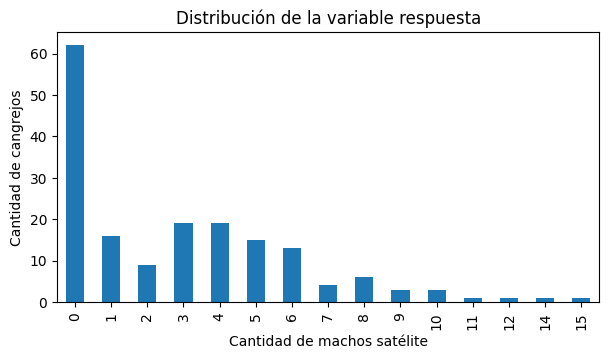

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))

crab["satellite"].value_counts().sort_index().plot(
    kind="bar",
    ax=ax
)

ax.set_xlabel("Cantidad de machos satélite")
ax.set_ylabel("Cantidad de cangrejos")
ax.set_title("Distribución de la variable respuesta")

plt.show()

¿Un modelo de Poisson simple es suficiente para describir esta distribución?

### Relación entre width y satellite



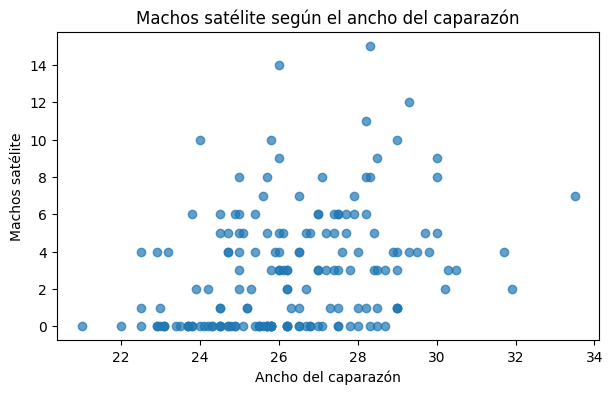

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    crab["width"],
    crab["satellite"],
    alpha=0.7
)

ax.set_xlabel("Ancho del caparazón")
ax.set_ylabel("Machos satélite")
ax.set_title("Machos satélite según el ancho del caparazón")

plt.show()

Y podemos incorporar el color:

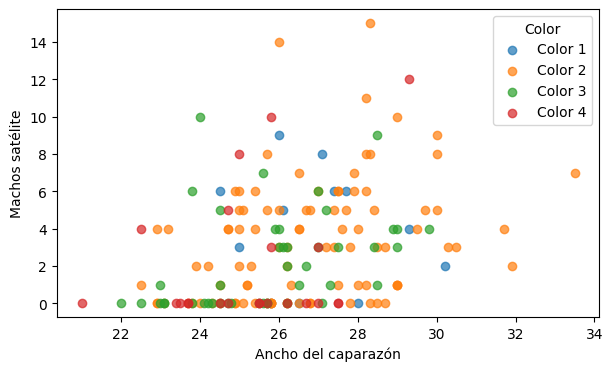

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

for color, grupo in crab.groupby("color"):
    ax.scatter(
        grupo["width"],
        grupo["satellite"],
        label=f"Color {color}",
        alpha=0.7
    )

ax.set_xlabel("Ancho del caparazón")
ax.set_ylabel("Machos satélite")
ax.legend(title="Color")

plt.show()

COnsideremos entonces:

$$ \log(\lambda_i) = \alpha+\beta_1\,width_i+\beta_2\,color_i $$

### Modelo Poisson

In [ ]:
model_pois = bmb.Model(
    "satellite ~ width + C(color)",
    family="poisson",
    data=crab
)

idata_pois = model_pois.fit(
    idata_kwargs={"log_likelihood": True},
    random_seed=123
)

Output()

Miramos los parámetros

In [ ]:
az.summary(
    idata_pois,
    var_names=["Intercept", "width"]
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-2.663,0.578,-3.763,-1.607,0.016,0.013,1305.0,1337.0,1.0
width,0.149,0.020,0.112,0.188,0.001,0.000,1402.0,1122.0,1.0


Y una gráfica especialmente útil para nosotros:

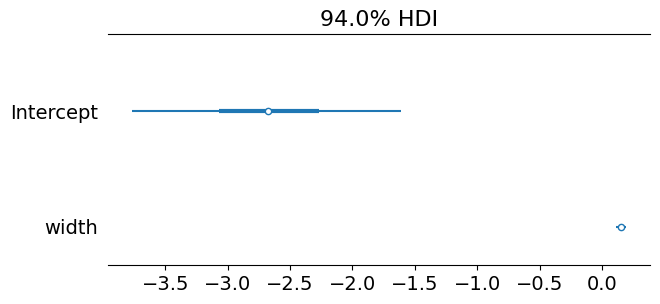

In [ ]:
az.plot_forest(
    idata_pois,
    var_names=["Intercept", "width"],
    combined=True,
    figsize=(7, 3)
)

plt.show()

Observación:

`width > 0` → a mayor ancho, aumenta la tasa esperada de satélites.
El coeficiente está en la escala logarítmica.

Por lo tanto,
$exp(β)$ representa un factor multiplicativo sobre la media.

### Predicciones del Poisson


In [ ]:
model_pois.predict(
    idata_pois,
    kind="pps"
)

/usr/local/lib/python3.12/dist-packages/bambi/models.py:858: FutureWarning: 'pps' has been replaced by 'response' and is not going to work in the future
  warnings.warn(


Y hacemos el PPC:

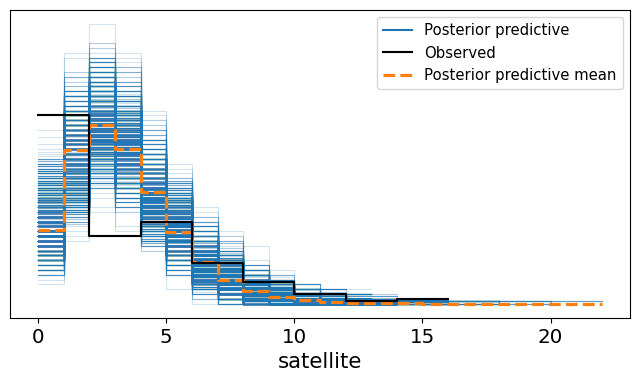

In [ ]:
az.plot_ppc(
    idata_pois,
    figsize=(8, 4)
)

plt.show()

Pero además podemos mirar observado vs. predicho.

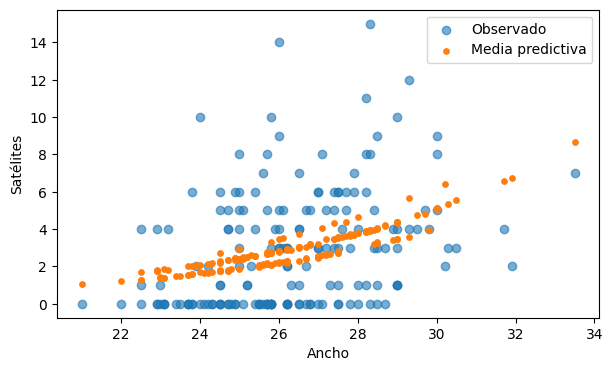

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    crab["width"],
    crab["satellite"],
    alpha=0.6,
    label="Observado"
)

# Media predictiva
mu_pred = (
    idata_pois.posterior_predictive["satellite"]
    .mean(dim=("chain", "draw"))
)

ax.scatter(
    crab["width"],
    mu_pred,
    s=15,
    label="Media predictiva"
)

ax.set_xlabel("Ancho")
ax.set_ylabel("Satélites")
ax.legend()

plt.show()



¿Qué patrón de los datos consigue reproducir el modelo?

### El problema de los ceros


In [ ]:
# Calculamos qué proporción de los cangrejos tiene cero machos satélite
(crab["satellite"] == 0).mean()

np.float64(0.3583815028901734)

Podemos comparar la proporción observada de ceros con la que genera el Poisson:

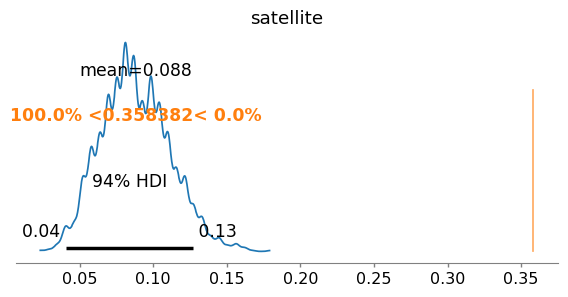

In [ ]:
y_rep = idata_pois.posterior_predictive["satellite"]

# Detectamos automáticamente la dimensión correspondiente a las observaciones
obs_dim = y_rep.dims[-1]

# Proporción de ceros en cada muestra predictiva
zero_rep = (y_rep == 0).mean(dim=obs_dim)

az.plot_posterior(
    zero_rep,
    ref_val=(crab["satellite"] == 0).mean(),
    figsize=(7, 3)
)

plt.show()

¿El modelo Poisson genera una cantidad de ceros compatible con la observada?


### Zero-Inflated Poisson

Recordemos:

$$ P(Y=0) = (1-\psi)+\psi P_{\text{Poisson}}(0) $$

y para \(y>0\):

$$ P(Y=y) = \psi P_{\text{Poisson}}(y) $$

El modelo nos queda:

In [ ]:
model_zip = bmb.Model(
    "satellite ~ width + C(color)",
    family="zero_inflated_poisson",
    data=crab
)

idata_zip = model_zip.fit(
    idata_kwargs={"log_likelihood": True},
    random_seed=123
)

Output()

REalizamos las predicciones:

In [ ]:
model_zip.predict(
    idata_zip,
    kind="pps"
)

/usr/local/lib/python3.12/dist-packages/bambi/models.py:858: FutureWarning: 'pps' has been replaced by 'response' and is not going to work in the future
  warnings.warn(


Y PPC:

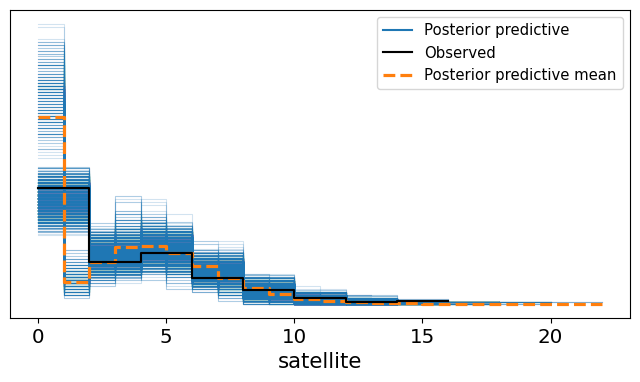

In [ ]:
az.plot_ppc(
    idata_zip,
    figsize=(8, 4)
)

plt.show()

### Comparamos Poisson y ZIP visualmente

Ponemos ambos PPC juntos:

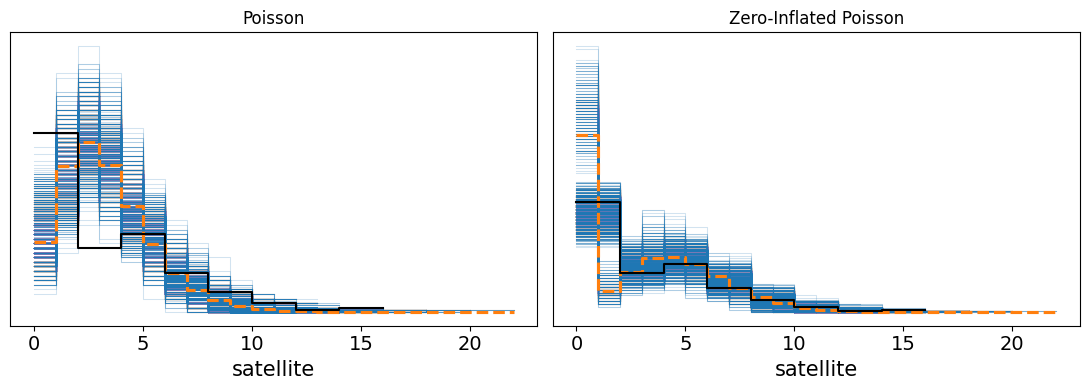

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

az.plot_ppc(
    idata_pois,
    ax=axes[0],
    legend=False
)

axes[0].set_title("Poisson")

az.plot_ppc(
    idata_zip,
    ax=axes[1],
    legend=False
)

axes[1].set_title("Zero-Inflated Poisson")

plt.tight_layout()
plt.show()

## Hurdle model

Un modelo Hurdle separa el problema en dos etapas:

1) ¿Se supera el obstáculo?
    
  $$P(Y>0)=\psi.$$

2) Si se supera, ¿cuál es el valor positivo?
    $$ Y\mid Y>0
    \sim \text{"distribución de conteo truncada en cero".}$$

Así tenemos que

$P(Y=0)=1-\psi$

y, para $y>0$,

$$P(Y=y)=\psi \frac{P_0(y)}
     {1-P_0(0)}.$$


En un modelo Hurdle, todos los ceros provienen del primer proceso, mientras que la distribución de conteo solo se utilizará para los valores positivos.

Modelizamos en Bambi:

In [ ]:
model_hurdle = bmb.Model(
    "satellite ~ width + C(color)",
    family="hurdle_poisson",
    data=crab
)

idata_hurdle = model_hurdle.fit(
    idata_kwargs={"log_likelihood": True},
    random_seed=123
)

Output()

Realizamos las predicciones:

In [ ]:
model_hurdle.predict(
    idata_hurdle,
    kind="pps"
)

/usr/local/lib/python3.12/dist-packages/bambi/models.py:858: FutureWarning: 'pps' has been replaced by 'response' and is not going to work in the future
  warnings.warn(


Trabajamos con las PPC:

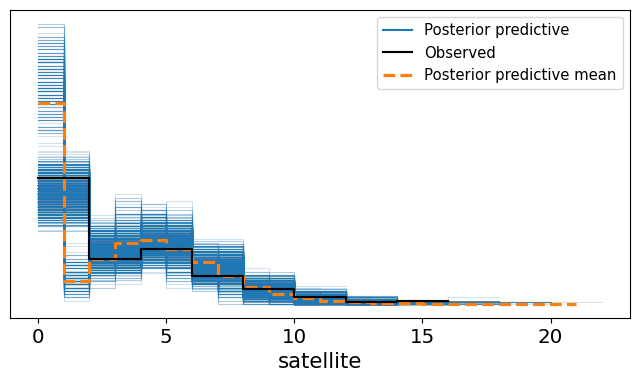

In [ ]:
az.plot_ppc(
    idata_hurdle,
    figsize=(8, 4)
)

plt.show()

### Comparamos modelos

En lugar de mirar tres modelos por separado, podemos hacer:

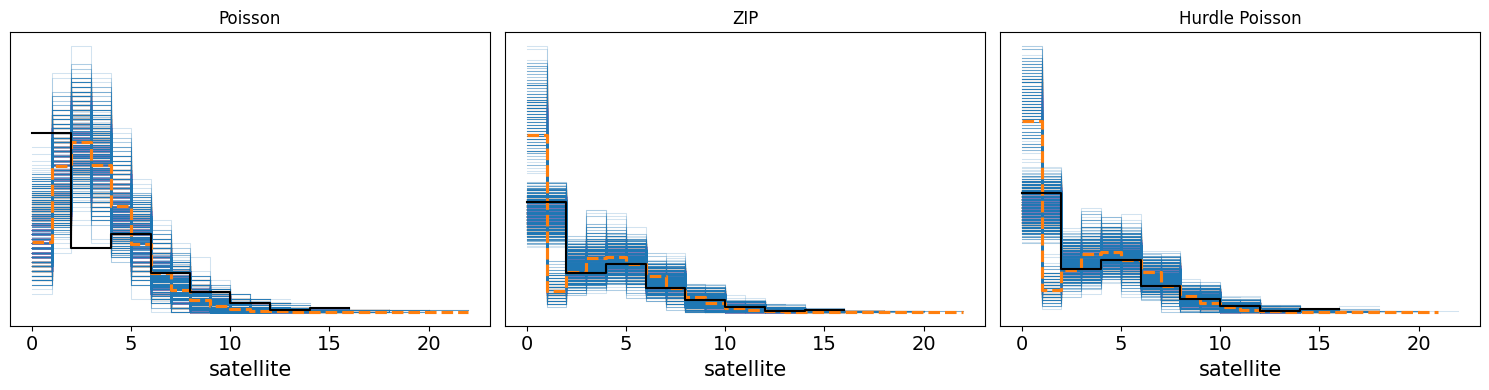

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for ax, idata, title in zip(
    axes,
    [idata_pois, idata_zip, idata_hurdle],
    ["Poisson", "ZIP", "Hurdle Poisson"]
):

    az.plot_ppc(
        idata,
        ax=ax,
        legend=False
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()

<font color="red"> Actividad:

¿Qué modelo reproduce mejor cada caso?:

Tener en cuenta:

* cantidad de ceros;
* frecuencia de valores pequeños;
* cola de la distribución;
* dispersión general.

¿Es suficiente esta manera de análisis para poder concluir?

### Comparación mediante LOO

In [ ]:
idatas = {
    "Poisson": idata_pois,
    "ZIP": idata_zip,
    "Hurdle": idata_hurdle
}

cmp = az.compare(idatas)

cmp

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
ZIP,0,-382.496308,9.276998,0.000000,0.000000,17.837099,0.000000,False,log
Hurdle,1,-382.533689,8.783165,0.037380,0.875912,17.747396,0.545587,False,log
Poisson,2,-468.513830,16.287896,86.017521,0.124088,24.895357,17.842335,False,log


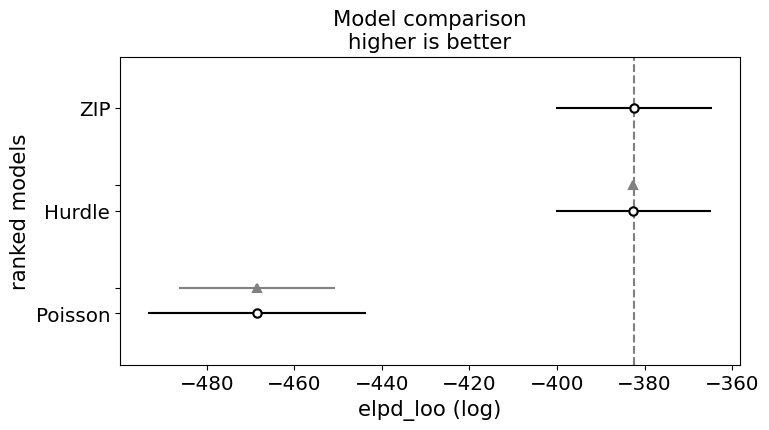

In [ ]:
az.plot_compare(
    cmp,
    figsize=(8, 4),
    plot_ic_diff=True
)

plt.show()

El LOO permite comparar modelos predictivamente, teniendo en cuenta cómo cada modelo explica las observaciones que dejamos fuera.

### Comparamos las distribuciones predictivas de manera directa:

In [ ]:
y_obs = crab["satellite"]

pred_pois = (
    idata_pois.posterior_predictive["satellite"]
    .stack(sample=("chain", "draw"))
    .values
    .flatten()
)

pred_zip = (
    idata_zip.posterior_predictive["satellite"]
    .stack(sample=("chain", "draw"))
    .values
    .flatten()
)

pred_hurdle = (
    idata_hurdle.posterior_predictive["satellite"]
    .stack(sample=("chain", "draw"))
    .values
    .flatten()
)

Graficamos:

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    sharey=True
)

for ax, pred, title in zip(
    axes,
    [pred_pois, pred_zip, pred_hurdle],
    ["Poisson", "ZIP", "Hurdle"]
):

    ax.hist(
        y_obs,
        bins=np.arange(y_obs.max() + 2) - 0.5,
        density=True,
        alpha=0.6,
        label="Observado"
    )

    ax.hist(
        pred,
        bins=np.arange(y_obs.max() + 2) - 0.5,
        density=True,
        alpha=0.4,
        label="Predictivo"
    )

    ax.set_title(title)
    ax.set_xlabel("Satélites")

axes[0].set_ylabel("Densidad")
axes[0].legend()

plt.tight_layout()
plt.show()

### ¿Dónde aparece la mezcla de modelos?

Observemos que en el Zero-Inflated Poisson sí hay una mezcla de dos mecanismos:

$$ Y \sim \begin{cases} 0, & \text{con probabilidad }1-\psi\\ \text{Poisson}(\lambda), & \text{con probabilidad }\psi \end{cases} $$

Por eso el ZIP puede interpretarse como una mezcla entre una distribución degenerada en 0 y una Poisson.

En cambio, el Hurdle no es una mezcla en el mismo sentido. Tiene dos etapas:

$$ P(Y=0)=1-\psi $$

y, si $Y>0$,
$$Y∼ \text{Poisson truncada en cero.}$$



In [ ]:
# Calculamos la proporción de observaciones que son cero
p0 = (crab["satellite"] == 0).mean()

# Mostramos la proporción de ceros y de valores positivos
print(f"Proporción de ceros: {p0:.2f}")
print(f"Proporción de valores positivos: {1-p0:.2f}")

Proporción de ceros: 0.36
Proporción de valores positivos: 0.64


Observen que acá simplemente calculamos cómo se divide nuestra muestra entre ceros y valores positivos. `p0` es la proporción observada de cangrejos que no tienen ningún macho satélite, y `1-p_0 `es la proporción que tiene al menos uno.

Esta separación es especialmente útil para entender el modelo Hurdle, porque plantea el problema en esos dos pasos:

* modelamos la probabilidad de ser cero o positivo.
* modelamos la cantidad de satélites entre las observaciones positivas.

### Dos mecanismos para generar los datos

En el modelo **Zero-Inflated Poisson**, suponemos que existen dos mecanismos:

- un mecanismo que produce ceros estructurales;
- un mecanismo Poisson que puede producir tanto ceros como valores positivos.

En el modelo **Hurdle**, en cambio, primero se determina si la observación es cero o positiva y, una vez superado ese umbral, se modela únicamente la distribución de los valores positivos.

Por eso, aunque ambos modelos permiten trabajar con exceso de ceros, la interpretación de los dos procesos es diferente.

Incorporemos los rotogramas para comparar los modelos estudiados.

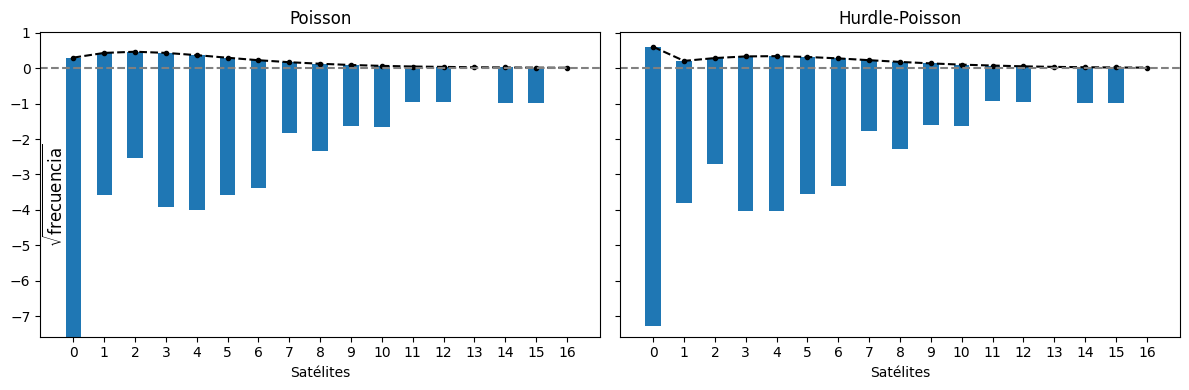

In [ ]:
def rotogram(idata, ax, y_obs):
    max_ = 17
    bins = np.arange(0, max_ + 1)

    # Distribución predictiva del modelo
    y_rep = idata.posterior_predictive["satellite"].values.ravel()

    n_samples = len(y_rep)
    pred = np.histogram(y_rep, bins=bins)[0] / n_samples
    observed = np.histogram(y_obs, bins=bins)[0]

    # Transformación raíz cuadrada
    pred = np.sqrt(pred)
    observed = np.sqrt(observed)

    # Barras: observados alrededor de la predicción
    ax.bar(
        bins[:-1],
        observed,
        width=0.5,
        bottom=pred - observed
    )

    # Predicción del modelo
    ax.plot(
        bins[:-1],
        pred,
        "k.--"
    )

    ax.axhline(0, linestyle="--", color="0.5")

    ax.set_xticks(bins[:-1])


fig, axes = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(12, 4)
)

rotogram(idata_pois, axes[0], crab["satellite"])
axes[0].set_title("Poisson")

rotogram(idata_hurdle, axes[1], crab["satellite"])
axes[1].set_title("Hurdle-Poisson")

axes[0].set_xlabel("Satélites")
axes[1].set_xlabel("Satélites")

fig.text(
    0.04, 0.5,
    r"$\sqrt{\mathrm{frecuencia}}$",
    va="center",
    rotation="vertical",
    fontsize=12
)

plt.tight_layout()
plt.show()

<font color="red"> Actividad:

comparen las frecuencias observadas con las que genera cada modelo. Prestá especial atención a los ceros, a los valores más frecuentes y a los conteos altos. ¿En qué valores cada modelo sobreestima o subestima los datos? ¿Observás algún patrón sistemático?

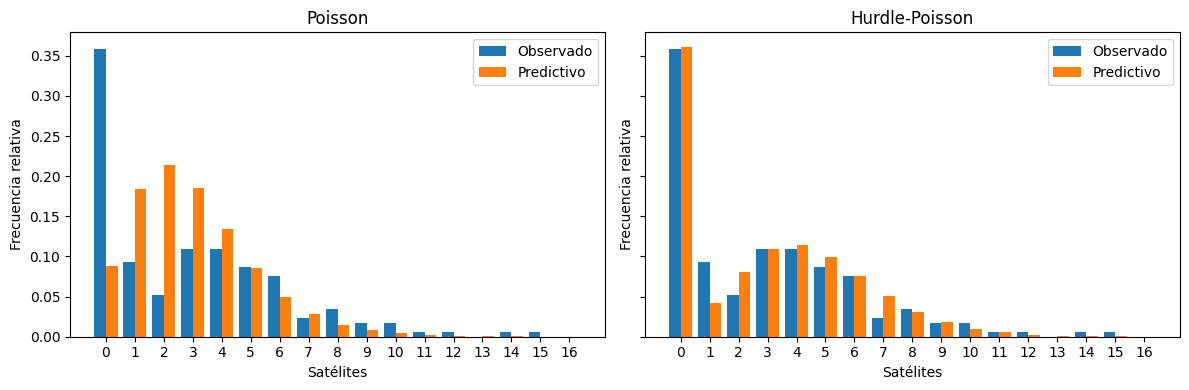

In [ ]:
def comparar_frecuencias(idata, ax, y_obs, titulo):

    # Valores simulados por el modelo
    y_rep = idata.posterior_predictive["satellite"].values.ravel()

    # Valores posibles
    valores = np.arange(0, 17)

    # Frecuencias relativas
    freq_obs = np.array([
        np.mean(y_obs == k)
        for k in valores
    ])

    freq_pred = np.array([
        np.mean(y_rep == k)
        for k in valores
    ])

    # Barras
    width = 0.4

    ax.bar(
        valores - width/2,
        freq_obs,
        width=width,
        label="Observado"
    )

    ax.bar(
        valores + width/2,
        freq_pred,
        width=width,
        label="Predictivo"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Satélites")
    ax.set_ylabel("Frecuencia relativa")
    ax.set_xticks(valores)
    ax.legend()


fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    sharey=True
)

comparar_frecuencias(
    idata_pois,
    axes[0],
    crab["satellite"].values,
    "Poisson"
)

comparar_frecuencias(
    idata_hurdle,
    axes[1],
    crab["satellite"].values,
    "Hurdle-Poisson"
)

plt.tight_layout()
plt.show()

# El proceso de Dirichlet

## Mezclas no finitas

Ahora volvemos a la pregunta que dejamos abierta antes. En una mezcla finita tenemos que elegir $K$, Pero en algunos casos podemos comparar distintos valores, e incluso a veces no queremos que el modelo dependa de una elección fija del número de componentes.

Para permitir potencialmente infinitos componentes, trabajaremos con mezclas no finitas, en las que no significa que vamos a terminar con infinitos grupos observados, sino que no ponemos un límite finito al número de componentes que el modelo puede considerar.

Una de las construcciones bayesianas más importantes para hacer esto es el ***Proceso de Dirichlet***.

$$G\sim DP(\alpha,H)$$

donde:

* $H$: distribución base;
* $\alpha$: parámetro de concentración;
* $G$: una \textbf{distribución aleatoria}.

Observen que el $DP$ no define directamente un conjunto fijo de parámetros, sino una distribución sobre posibles distribuciones. Es decir, $H$ representa el comportamiento medio alrededor del cual
se construye $G$.

**¿Qué hace el parámetro $\alpha$?**

Podemos pensarlo como un parámetro que controla la concentración alrededor de $H$.Esto es: con un $\alpha$ pequeño, las realizaciones de $G$ pueden alejarse más de $H$ y tenemos mayor variabilidad, mientras que con un $\alpha$ grande, $G$ tiende a parecerse más a la distribución base.

Hay además otra interpretación cuando usamos el proceso para construir agrupamientos: $\alpha$ influye en cuántos grupos terminan siendo utilizados por los datos.
No es que $\alpha$ “es” el número de grupos, sino un parámetro que controla la concentración del proceso y, como consecuencia, afecta también la tendencia a crear nuevos grupos.


**¿Por qué decimos que es una mezcla *infinita*?**


Si utilizamos $G$ como distribución de los parámetros:

$$
\theta_i\sim G,
\qquad
y_i\mid\theta_i\sim p(y_i\mid\theta_i),
$$

entonces:

$$
G=\sum_{k=1}^{\infty}w_k\delta_{\theta_k}.
$$

Esto equivale a tener potencialmente infinitos componentes. En la práctica, una muestra finita de datos puede utilizar solamente una cantidad finita de componentes. Por eso el modelo puede adaptar el número efectivo de grupos a la información disponible, sin fijar $K$ previamente.


Un proceso de Dirichlet genera una distribución que puede tener una cantidad potencialmente infinita de componentes. En la práctica, los pesos más pequeños hacen que podamos trabajar con una cantidad finita de componentes.

1. Simulamos los pesos

Primero podemos mostrar solamente cómo se construyen los pesos $w_i$.

In [ ]:

def stick_breaking(alpha, n_componentes=20):

    beta = np.random.beta(1, alpha, size=n_componentes)
    pesos = []
    restante = 1

    for b in beta:
        w = b * restante
        pesos.append(w)
        restante *= (1 - b)

    return np.array(pesos)

Y probamos distintos valores de $\alpha$:

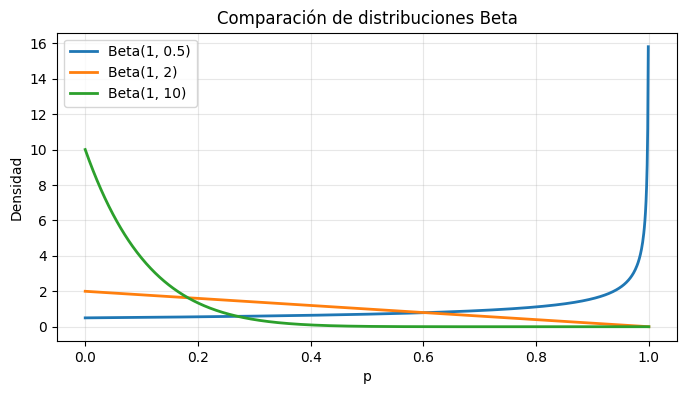

In [ ]:
# @title
# graficamos las distribuciones betas:
x = np.linspace(0, 1, 1000)

parametros = [
    (1, 0.5), # alpha= 0.5
    (1, 2),   # alpha= 2
    (1, 10)   # alpha= 10
]

plt.figure(figsize=(8, 4))

for a, b in parametros:
    pdf = beta.pdf(x, a, b)
    plt.plot(x, pdf, linewidth=2, label=f'Beta({a}, {b})')

plt.xlabel('p')
plt.ylabel('Densidad')
plt.title('Comparación de distribuciones Beta')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

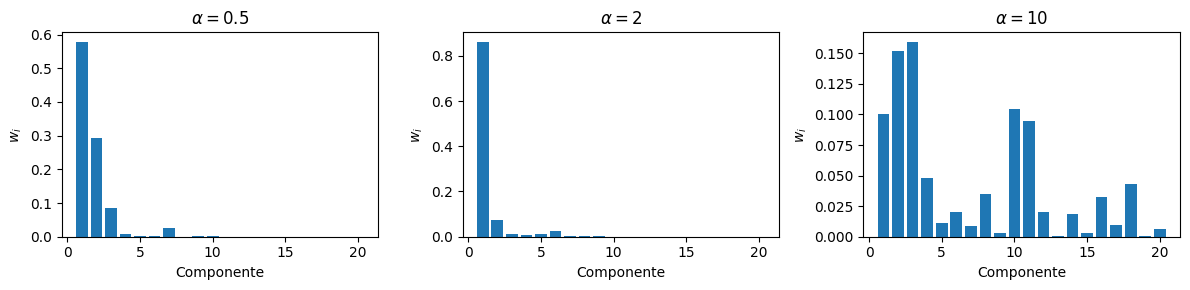

In [ ]:
alphas = [0.5, 2, 10]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, alpha in zip(axes, alphas):

    pesos = stick_breaking(alpha)

    ax.bar(range(1, len(pesos) + 1), pesos)
    ax.set_title(rf"$\alpha={alpha}$")
    ax.set_xlabel("Componente")
    ax.set_ylabel(r"$w_i$")

plt.tight_layout()

*Respondan:* ¿Qué cambia cuando aumenta $\alpha$?



2. Relación con un modelo de mezcla

En un modelo de mezcla finita teníamos algo como:

$$ p(x)=\sum_{k=1}^{K}w_k f(x\mid\theta_k) $$

donde $K$ era fijo.

Con el proceso de Dirichlet:

$$ G=\sum_{i=1}^{\infty}w_i\delta_{\theta_i} $$

y podemos pensar intuitivamente que los pesos $w_i$ son los pesos de infinitas componentes.

Para visualizarlo, podemos asignar a cada componente una media $\theta_i$ y construir una mezcla de normales:

In [ ]:
def mezcla_dirichlet(alpha, n_componentes=20, n=1000):

    pesos = stick_breaking(alpha, n_componentes)

    theta = np.random.normal(0, 4, n_componentes)

    componentes = np.random.choice(
        n_componentes,
        size=n,
        p=pesos / pesos.sum()
    )

    x = np.random.normal(theta[componentes],  0.5)

    return x, pesos, theta

Y visualizamos:

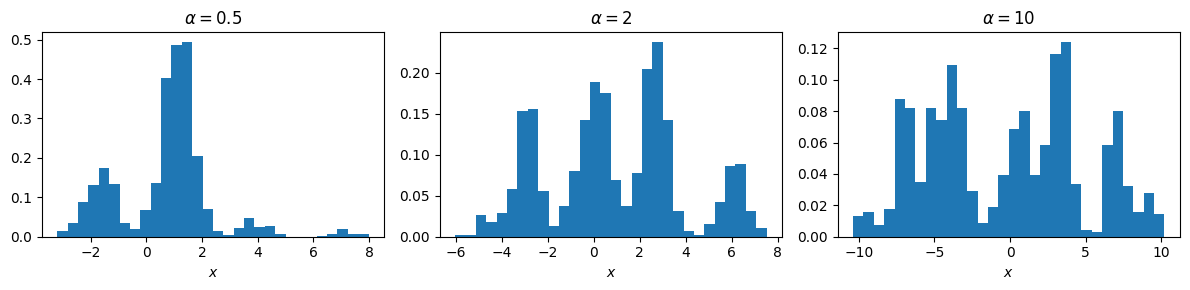

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, alpha in zip(axes, [0.5, 2, 10]):

    x, pesos, theta = mezcla_dirichlet(alpha)

    ax.hist(x, bins=30, density=True)
    ax.set_title(rf"$\alpha={alpha}$")
    ax.set_xlabel("$x$")

plt.tight_layout()

# Mezclas continuas

Hasta ahora las mezclas que vimos tenían una variable latente discreta: elegíamos uno entre varios componentes.

$$
p(y)
=
\sum_{k=1}^{K}
w_k\,p(y\mid\theta_k).
$$

Pero también podemos considerar que $\theta$ toma valores continuos:

$$
p(y)
=
\int
p(y\mid\theta)\,g(\theta)\,d\theta
$$


En lugar de elegir entre un conjunto discreto de valores de un parámetro $\theta$, podemos pensar que ese parámetro toma valores continuos y
*promediamos* sobre todos los valores posibles de $\theta$,
ponderados por $g(\theta)$.

Esto se conoce como *mezcla continua*.

Por eso aparece una integral en lugar de una suma. La expresión dice, en esencia, que para cada posible valor de $\theta$, calculamos qué tan probable sería observar $y$ y luego realizamos un promedio ponderado utilizando $g(\theta)$.


### Resumen de ejemplos:

**i) Beta-Binomial**

Supongamos que

$$p\sim Beta(\alpha,\beta)
$$
$$
Y\mid p\sim Binomial(n,p).
$$

Al integrar $p$ obtenemos:

$$P(Y=y)
=
\int_0^1
P(Y=y\mid p)\,p(p)\,dp$$

Por lo tanto, la Beta-Binomial puede verse como una mezcla continua de Binomiales. No estamos fijandos una única probabilidad $p$, sino que promediamos sobre los valores posibles de $p$.

**ii) Gamma-Poisson**

Teniendo
$$
\lambda\sim Gamma(α,β),
\qquad
Y\mid\lambda\sim Poisson(\lambda).
$$

Al integrar $\lambda$ obtenemos una distribución marginal que
puede presentar sobredispersión:

$$Var(Y)>\mathbb E[Y].$$

**iii) Normal-Gamma**

$$
\lambda\sim Gamma\left(\frac{\nu}{2},\frac{\nu}{2}\right),
\qquad
Y\mid\lambda
\sim
\mathcal N\left(\mu,\frac{\sigma^2}{\lambda}\right).$$

Al integrar $\lambda$ obtenemos una distribución
$t$ de Student, con colas más pesadas que una Normal.

